# Árboles de decisión

#### Ejemplo de uso en Python (clasificación):
Un ejemplo clásico es predecir la supervivencia en el desastre del Titanic, donde las decisiones se basan en atributos discretos y continuos como la edad y el sexo.

Utilizamos la librería scikit-learn en Python para construir el árbol. En este ejemplo, el árbol se entrena para decidir si un pasajero sobrevive (Sí) o no (No), basándose en el sexo y la edad.

1. **Preparación de Datos**: Se definen los atributos de entrada (X) y el resultado esperado (y). (Asumimos que 'Sex_male' ha sido codificado como 0 o 1).
2. **Construcción y Entrenamiento**: Se importa la clase DecisionTreeClassifier y se ajusta el modelo a los datos de entrenamiento

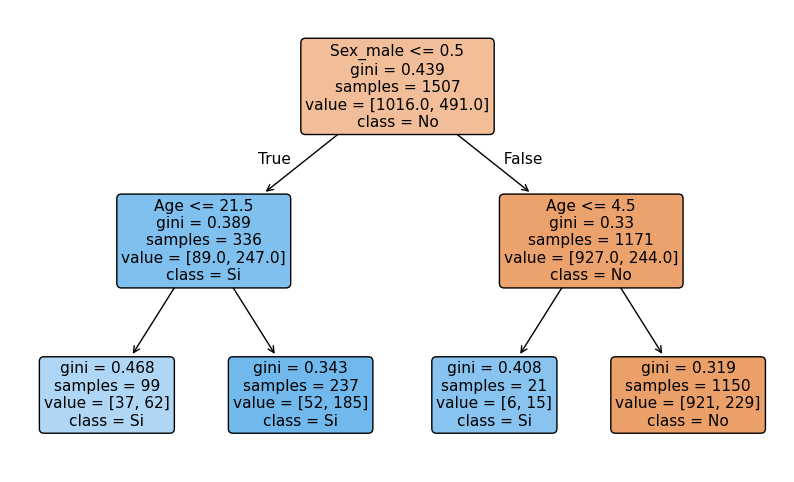

In [2]:
# EJEMPLO CONCEPTUAL EN PYTHON USANDO SCIKIT-LEARN

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

df = pd.read_csv('https://patricioaraneda.cl/public/titanic5_full.csv')
df = df[['Survived', 'Age', 'Sex']].dropna(subset=['Survived', 'Age', 'Sex'])

# Codificar sexo (male=1, female=0)
# Si 'Sex' ya está codificado como 0/1, el mapeo dará NaN; rellenamos con el valor original en ese caso.
df['Sex_male'] = df['Sex'].map({'male': 1, 'female': 0})
df['Sex_male'] = df['Sex_male'].fillna(df['Sex']).astype(float)

# Simulación de datos: [Edad, Sexo (1=Masculino, 0=Femenino)]
# En un caso real, esto provendría del dataset de Titanic
X_data = df[['Age', 'Sex_male']].values
# Etiquetas: 1=Sobrevive, 0=No Sobrevive
y_labels = df['Survived'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(X_data, y_labels, test_size=0.3, random_state=42)

# --- Crear y Entrenar el Modelo ---
# Limitamos la profundidad para evitar el sobreajuste (max_depth=2) [15]
clf = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=0)
clf.fit(X_train, y_train) 

# --- Visualización del Árbol ---
# plot_tree fue importado de sklearn.tree arriba.
plt.figure(figsize=(10,6))
# X_data es un numpy.ndarray, no tiene .columns => pasamos los nombres de las características explícitamente
plot_tree(clf, feature_names=['Age', 'Sex_male'], class_names=['No', 'Si'], filled=True, rounded=True)
plt.show()
# Esta función generaría un diagrama donde se ve:
# 1. El nodo raíz dividiendo por 'Sex_male' (porque es el atributo más importante, como se ve en el ejemplo real).
# 2. Las siguientes divisiones basadas en 'Age'.

Accuracy: 0.7650695517774343
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       437
           1       0.69      0.50      0.58       210

    accuracy                           0.77       647
   macro avg       0.74      0.70      0.71       647
weighted avg       0.76      0.77      0.75       647

Age: 0.1783
Sex_male: 0.8217


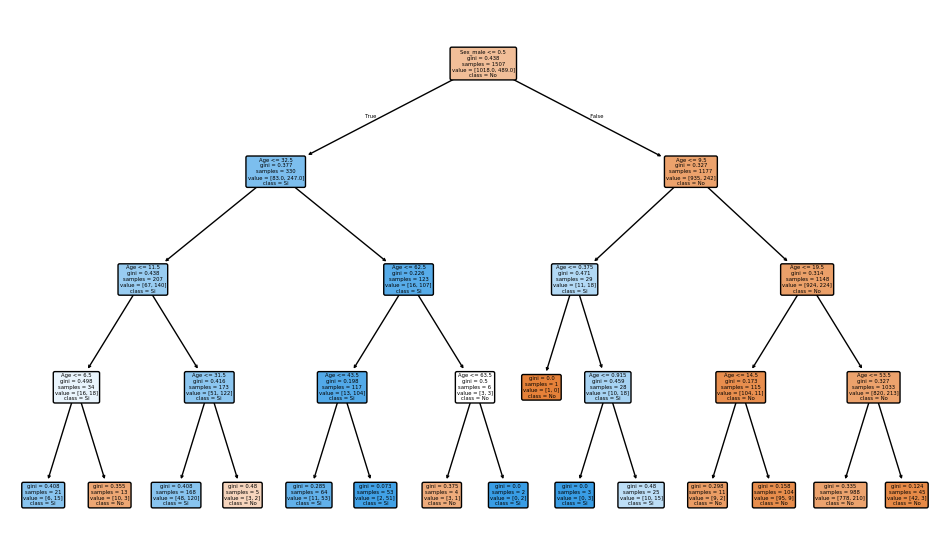

In [3]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Cargar y preparar datos
import requests

df = pd.read_csv('https://patricioaraneda.cl/public/titanic5_full.csv')
df = df[['Survived', 'Age', 'Sex']].dropna(subset=['Survived', 'Age', 'Sex'])

# Codificar sexo (male=1, female=0)
df['Sex_male'] = df['Sex'].map({'male': 1, 'female': 0})

# Características y etiqueta
X_t = df[['Age', 'Sex_male']].values
y_t = df['Survived'].astype(int).values

# División entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(X_t, y_t, test_size=0.3, random_state=42, stratify=y_t)

# Entrenar árbol de decisión
clf = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=0)
clf.fit(X_train, y_train)

# Evaluación
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# importancia de características
importances = clf.feature_importances_
feature_names = ['Age', 'Sex_male']
for name, importance in zip(feature_names, importances):
    print(f"{name}: {importance:.4f}")


# Visualizar árbol

plt.figure(figsize=(12,7))
plot_tree(clf, feature_names=['Age','Sex_male'], class_names=['No','Si'], filled=True, rounded=True)
plt.show()
# El árbol resultante mostraría cómo las decisiones se basan en estos atributos para predecir la supervivencia

### Prediccion sobre arbol de decisión

In [4]:
# genera una predicion para un pasajero de 25 años y sexo masculino
sample_passenger = np.array([[25, 1]])  # 25 años, masculino
predicted_survival = clf.predict(sample_passenger)
print(f"Predicción de supervivencia para pasajero de 25 años y sexo masculino: {'Sobrevive' if predicted_survival[0] == 1 else 'No Sobrevive'}")

Predicción de supervivencia para pasajero de 25 años y sexo masculino: No Sobrevive


In [5]:
# genera predicciones para pasajeros con diferentes edades y sexos
sample_passengers = np.array([[22, 0],  # 22 años, masculino
                              [30, 1],  # 30 años, femenino
                              [40, 1],  # 40 años, masculino
                              [35, 0]]) # 25 años, femenino
predicted_survivals = clf.predict(sample_passengers)
print("Predicciones de supervivencia para pasajeros de diferentes edades y sexos:")
for i, passenger in enumerate(sample_passengers):
    age, sex = passenger
    survival = 'Sobrevive' if predicted_survivals[i] == 1 else 'No Sobrevive'
    print(f"{age} años y sexo {'masculino' if sex == 1 else 'femenino'}: {survival}")


Predicciones de supervivencia para pasajeros de diferentes edades y sexos:
22 años y sexo femenino: Sobrevive
30 años y sexo masculino: No Sobrevive
40 años y sexo masculino: No Sobrevive
35 años y sexo femenino: Sobrevive


#### Ejemplo de uso en Python (regresión):

In [9]:
from sklearn.tree import DecisionTreeRegressor

# Datos de ejemplo

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1.2, 1.9, 3.0, 3.9, 5.1])

# Entrenamiento del árbol

reg = DecisionTreeRegressor()
reg.fit(X, y)

# Predicción

print(reg.predict([[3.5]]))  # Salida aproximada: [3.0 o 3.9]

[3.]


## Aplicaciones comunes

- Diagnóstico médico (clasificación de enfermedades)
- Detección de fraude
- Predicción de abandono de clientes (*churn*)
- Segmentación de clientes en marketing
- Predicción de precios de viviendas (regresión)

Los árboles de decisión son la base de algoritmos más avanzados como Random Forest y Gradient Boosting. Su principal ventaja es la interpretabilidad y facilidad de visualización, aunque pueden sobreajustar si no se podan o regulan adecuadamente.

---

### Deteccion de fraude

DIAGNÓSTICO DEL ÁRBOL SIN RESTRICCIÓN (OVERFITTED)
Profundidad máxima alcanzada: 21
Número total de hojas:        102
F1-Score en Entrenamiento:    100.00% (Memorización perfecta)
F1-Score en Prueba (Test):    50.85%
Brecha de sobreajuste (Gap):  49.15 puntos porcentuales

MODELO PODADO ÓPTIMO (ccp_alpha = 0.00054)
Profundidad reducida:         20 (frente a 21)
Número de hojas reducido:     85 (frente a 102)
F1-Score en Test (Generalizado): 50.00% (Mejora frente a 50.85%)


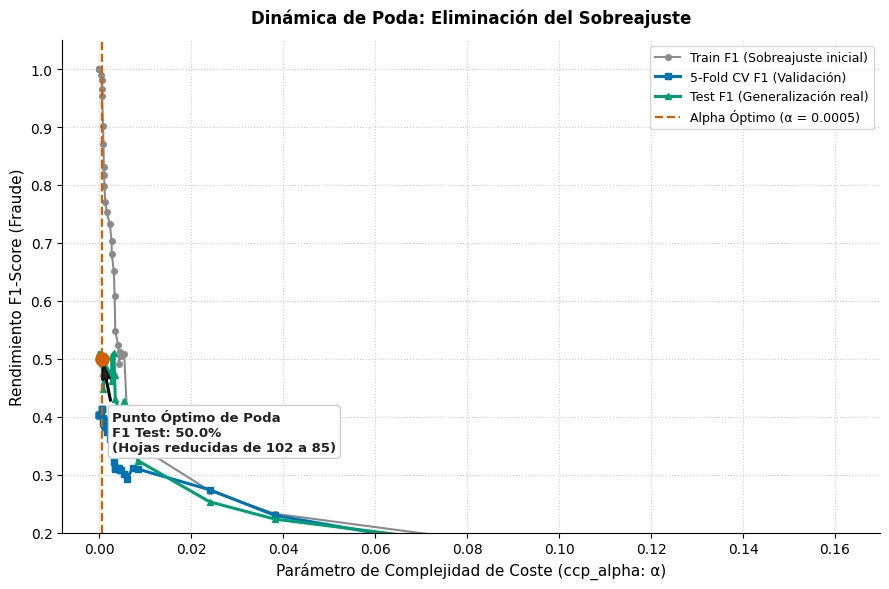

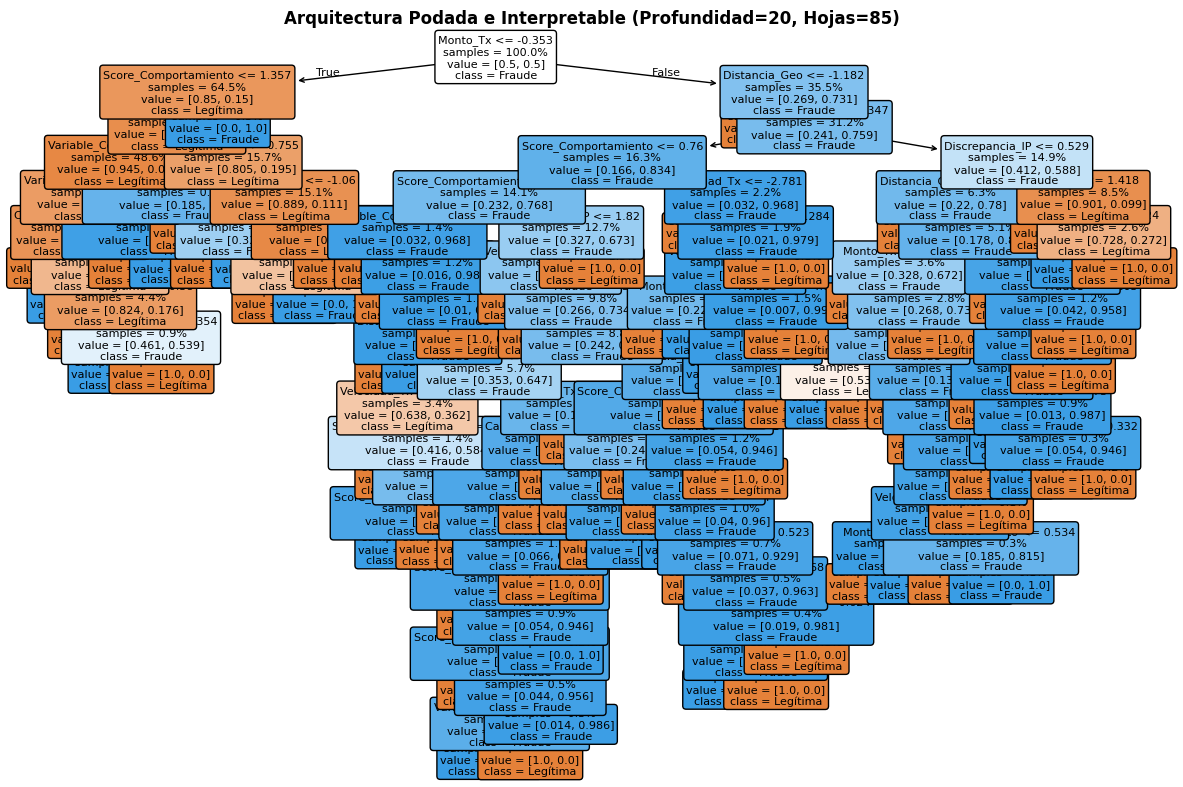

In [5]:
"""
Detección de Fraude con Árboles de Decisión.
Diagnóstico de Sobreajuste y Poda por Complejidad de Coste (Cost-Complexity Pruning).
Librerías: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import f1_score, roc_auc_score, classification_report

# ==============================================================================
# 1. Simulación de Datos de Transacciones Financieras (5% Fraude)
# ==============================================================================
np.random.seed(42)
X, y = make_classification(
    n_samples=2500,
    n_features=8,
    n_informative=5,
    n_redundant=2,
    weights=[0.95, 0.05],  # Desbalance severo de clases
    random_state=42
)

nombres_variables = [
    'Monto_Tx', 'Distancia_Geo', 'Frecuencia_24h', 
    'Discrepancia_IP', 'Velocidad_Tx', 'Score_Comportamiento',
    'Canal_Digital', 'Variable_Control'
]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ==============================================================================
# 2. Árbol Completo (Sin Poda) y Diagnóstico de Sobreajuste
# ==============================================================================
# Usamos class_weight='balanced' para compensar el desbalance del 5% de fraude
tree_sin_podar = DecisionTreeClassifier(random_state=42, class_weight='balanced')
tree_sin_podar.fit(X_train, y_train)

f1_train_sin_poda = f1_score(y_train, tree_sin_podar.predict(X_train))
f1_test_sin_poda = f1_score(y_test, tree_sin_podar.predict(X_test))
profundidad_max = tree_sin_podar.get_depth()
hojas_max = tree_sin_podar.get_n_leaves()

print("=" * 65)
print("DIAGNÓSTICO DEL ÁRBOL SIN RESTRICCIÓN (OVERFITTED)")
print("=" * 65)
print(f"Profundidad máxima alcanzada: {profundidad_max}")
print(f"Número total de hojas:        {hojas_max}")
print(f"F1-Score en Entrenamiento:    {f1_train_sin_poda*100:.2f}% (Memorización perfecta)")
print(f"F1-Score en Prueba (Test):    {f1_test_sin_poda*100:.2f}%")
print(f"Brecha de sobreajuste (Gap):  {(f1_train_sin_poda - f1_test_sin_poda)*100:.2f} puntos porcentuales\n")

# ==============================================================================
# 3. Trayectoria de Poda por Complejidad de Coste (Cost-Complexity Pruning)
# ==============================================================================
# Extraemos los valores críticos de alpha generados por el algoritmo CART
path = tree_sin_podar.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

# Submuestreamos alphas para evaluar computacionalmente una rejilla homogénea
alphas_grid = ccp_alphas[::max(1, len(ccp_alphas)//25)]
if alphas_grid[-1] != ccp_alphas[-1]:
    alphas_grid = np.append(alphas_grid, ccp_alphas[-1])

train_scores, cv_scores, test_scores = [], [], []

for alpha in alphas_grid:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha, class_weight='balanced')
    clf.fit(X_train, y_train)
    
    train_scores.append(f1_score(y_train, clf.predict(X_train)))
    test_scores.append(f1_score(y_test, clf.predict(X_test)))
    
    # 5-Fold Cross-Validation para seleccionar el mejor alpha sin fuga de datos
    score_cv = cross_val_score(clf, X_train, y_train, cv=5, scoring='f1').mean()
    cv_scores.append(score_cv)

train_scores = np.array(train_scores)
cv_scores = np.array(cv_scores)
test_scores = np.array(test_scores)

# Selección del alpha óptimo basado en el máximo rendimiento de validación cruzada
best_idx = np.argmax(cv_scores)
best_alpha = alphas_grid[best_idx]

# Ajuste del modelo final podado
tree_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha, class_weight='balanced')
tree_podado.fit(X_train, y_train)

f1_test_podado = f1_score(y_test, tree_podado.predict(X_test))
profundidad_podado = tree_podado.get_depth()
hojas_podado = tree_podado.get_n_leaves()

print("=" * 65)
print(f"MODELO PODADO ÓPTIMO (ccp_alpha = {best_alpha:.5f})")
print("=" * 65)
print(f"Profundidad reducida:         {profundidad_podado} (frente a {profundidad_max})")
print(f"Número de hojas reducido:     {hojas_podado} (frente a {hojas_max})")
print(f"F1-Score en Test (Generalizado): {f1_test_podado*100:.2f}% (Mejora frente a {f1_test_sin_poda*100:.2f}%)")
print("=" * 65)

# ==============================================================================
# 4. Gráficos separados
# ==============================================================================

# Panel 1: Curva de Poda de Coste-Complejidad
fig1, ax1 = plt.subplots(figsize=(9, 6), facecolor='white')
ax1.set_facecolor('white')

ax1.plot(alphas_grid, train_scores, marker='o', markersize=4,
         color='#8a8a8a', label='Train F1 (Sobreajuste inicial)')
ax1.plot(alphas_grid, cv_scores, marker='s', markersize=5,
         color='#0072b2', linewidth=2.2, label='5-Fold CV F1 (Validación)')
ax1.plot(alphas_grid, test_scores, marker='^', markersize=5,
         color='#009e73', linewidth=2.2, label='Test F1 (Generalización real)')

ax1.axvline(best_alpha, color='#d55e00', linestyle='--', linewidth=1.6,
            label=f'Alpha Óptimo (α = {best_alpha:.4f})')
ax1.scatter([best_alpha], [f1_test_podado], color='#d55e00', s=90, zorder=5)

ax1.annotate(
    f'Punto Óptimo de Poda\nF1 Test: {f1_test_podado*100:.1f}%\n'
    f'(Hojas reducidas de {hojas_max} a {hojas_podado})',
    xy=(best_alpha, f1_test_podado),
    xytext=(best_alpha * 1.5 + 0.002, f1_test_podado - 0.16),
    arrowprops=dict(facecolor='#222222', shrink=0.08, width=1.2, headwidth=6),
    fontweight='bold', fontsize=9.5, color='#222222',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#cccccc')
)

ax1.set_title("Dinámica de Poda: Eliminación del Sobreajuste",
              fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel("Parámetro de Complejidad de Coste (ccp_alpha: α)", fontsize=11)
ax1.set_ylabel("Rendimiento F1-Score (Fraude)", fontsize=11)
ax1.set_ylim(0.2, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9)

fig1.tight_layout()
plt.show()


# Panel 2: Arquitectura del Árbol Podado
fig2, ax2 = plt.subplots(figsize=(12, 8), facecolor='white')
ax2.set_facecolor('white')
plot_tree(
    tree_podado,
    feature_names=nombres_variables,
    class_names=['Legítima', 'Fraude'],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax2,
    impurity=False,
    proportion=True
)
ax2.set_title(
    f"Arquitectura Podada e Interpretable "
    f"(Profundidad={profundidad_podado}, Hojas={hojas_podado})",
    fontsize=12, fontweight='bold', pad=12
)

fig2.tight_layout()
plt.show()

### diagnostico medico

Dimensiones del dataset real: (569, 30) instancias y (569, 30) características.

REPORTE DE CLASIFICACIÓN CLÍNICA EN DATOS DE PRUEBA (TEST)
              precision    recall  f1-score   support

     Maligno      0.921     0.906     0.913        64
     Benigno      0.944     0.953     0.949       107

    accuracy                          0.936       171
   macro avg      0.933     0.930     0.931       171
weighted avg      0.936     0.936     0.936       171

Matriz de Confusión:
Verdaderos Malignos (Aciertos): [[ 58   6]
 [  5 102]] | Falsos Benignos (Omisiones críticas): [[ 58   6]
 [  5 102]]
Falsos Malignos (Falsas alarmas): [[ 58   6]
 [  5 102]] | Verdaderos Benignos (Aciertos): [[ 58   6]
 [  5 102]]


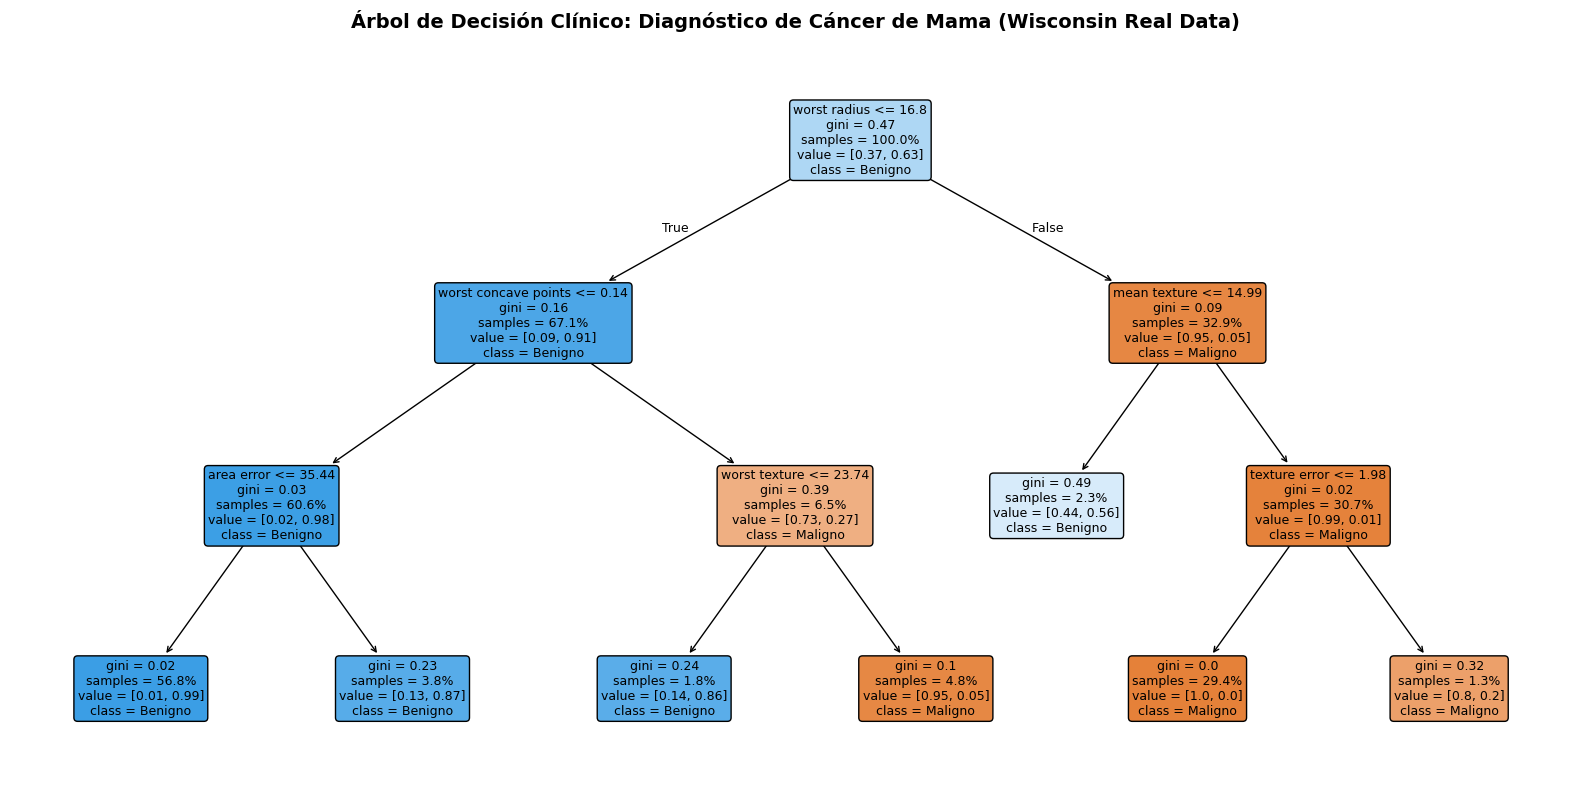

In [4]:
"""
Árbol de Decisión para Diagnóstico Médico Real.
Dataset: Breast Cancer Wisconsin (Diagnostic) - scikit-learn.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix

# ==============================================================================
# 1. Carga de Datos Clínicos Reales
# ==============================================================================
data = load_breast_cancer()
X = data.data
y = data.target  # 0: Maligno, 1: Benigno
nombres_caracteristicas = data.feature_names
nombres_clases = ['Maligno', 'Benigno']

print(f"Dimensiones del dataset real: {X.shape} instancias y {X.shape} características.")

# Partición estratificada (70% Train, 30% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Ajuste del Árbol de Decisión Clínico (Interpretable)
# ==============================================================================
# Configuramos max_depth=3 para evitar el sobreajuste y permitir auditoría médica
arbol_medico = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
arbol_medico.fit(X_train, y_train)

# Predicción y métricas de desempeño
y_pred = arbol_medico.predict(X_test)

print("\n" + "=" * 60)
print("REPORTE DE CLASIFICACIÓN CLÍNICA EN DATOS DE PRUEBA (TEST)")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=3))

cm = confusion_matrix(y_test, y_pred)
print("Matriz de Confusión:")
print(f"Verdaderos Malignos (Aciertos): {cm} | Falsos Benignos (Omisiones críticas): {cm}")
print(f"Falsos Malignos (Falsas alarmas): {cm} | Verdaderos Benignos (Aciertos): {cm}")

# ==============================================================================
# 3. Visualización Gráfica del Árbol de Decisión (Fondo Blanco Plano)
# ==============================================================================
fig, ax = plt.subplots(figsize=(16, 8), facecolor='white')
ax.set_facecolor('white')

# Renderizado de la arquitectura del árbol con Scikit-Learn
plot_tree(
    arbol_medico,
    feature_names=nombres_caracteristicas,
    class_names=nombres_clases,
    filled=True,
    rounded=True,
    precision=2,
    fontsize=9,
    ax=ax,
    proportion=True  # Muestra proporciones relativas en cada nodo
)

ax.set_title(
    "Árbol de Decisión Clínico: Diagnóstico de Cáncer de Mama (Wisconsin Real Data)",
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
plt.show()

### Curva de Validación de Profundidad vs. Error

=== EVALUACIÓN DEL IMPACTO DE LA PROFUNDIDAD ===
Profundidad:  1 | Train Acc:  92.7% | CV Acc:  90.5% | Test Acc:  91.2%
Profundidad:  2 | Train Acc:  96.5% | CV Acc:  94.0% | Test Acc:  91.8%
Profundidad:  3 | Train Acc:  98.0% | CV Acc:  94.2% | Test Acc:  92.4%
Profundidad:  4 | Train Acc:  99.2% | CV Acc:  93.5% | Test Acc:  92.4%
Profundidad:  5 | Train Acc:  99.5% | CV Acc:  93.2% | Test Acc:  93.0%
Profundidad:  6 | Train Acc: 100.0% | CV Acc:  93.5% | Test Acc:  91.8%
Profundidad:  7 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%
Profundidad:  8 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%
Profundidad:  9 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%
Profundidad: 10 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%
Profundidad: 11 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%
Profundidad: 12 | Train Acc: 100.0% | CV Acc:  92.5% | Test Acc:  91.8%

Profundidad óptima identificada por Validación Cruzada: max_depth = 3


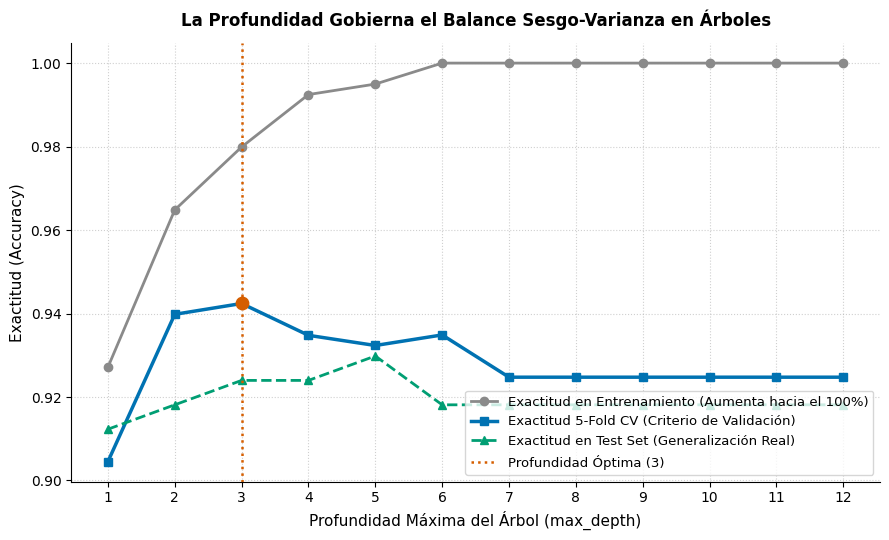

In [7]:
"""
Impacto de la Profundidad en el Rendimiento Generalizador.
Dataset: Breast Cancer Wisconsin (scikit-learn).
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# 1. Carga de datos reales y partición Train / Test
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Evaluación paramétrica de la profundidad (max_depth de 1 a 12)
profundidades = np.arange(1, 13)
train_scores = []
cv_scores = []
test_scores = []

for d in profundidades:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    
    # Rendimiento aparente en entrenamiento
    train_scores.append(clf.score(X_train, y_train))
    
    # Rendimiento en 5-Fold Cross-Validation (Métrica de Selección)
    cv_mean = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy').mean()
    cv_scores.append(cv_mean)
    
    # Rendimiento real en el conjunto de prueba independiente
    test_scores.append(clf.score(X_test, y_test))

# 3. Identificación del punto óptimo de generalización
mejor_idx = np.argmax(cv_scores)
profundidad_optima = profundidades[mejor_idx]

print("=== EVALUACIÓN DEL IMPACTO DE LA PROFUNDIDAD ===")
for d, tr, cv, te in zip(profundidades, train_scores, cv_scores, test_scores):
    print(f"Profundidad: {d:2d} | Train Acc: {tr*100:5.1f}% | CV Acc: {cv*100:5.1f}% | Test Acc: {te*100:5.1f}%")

print(f"\nProfundidad óptima identificada por Validación Cruzada: max_depth = {profundidad_optima}")

# 4. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor='white')
ax.set_facecolor('white')

ax.plot(profundidades, train_scores, marker='o', color='#8a8a8a', linewidth=2, label='Exactitud en Entrenamiento (Aumenta hacia el 100%)')
ax.plot(profundidades, cv_scores, marker='s', color='#0072b2', linewidth=2.5, label='Exactitud 5-Fold CV (Criterio de Validación)')
ax.plot(profundidades, test_scores, marker='^', color='#009e73', linewidth=2, linestyle='--', label='Exactitud en Test Set (Generalización Real)')

# Indicador del punto óptimo
ax.axvline(profundidad_optima, color='#d55e00', linestyle=':', linewidth=1.8, label=f'Profundidad Óptima ({profundidad_optima})')
ax.scatter([profundidad_optima], [cv_scores[mejor_idx]], color='#d55e00', s=80, zorder=5)

ax.set_title("La Profundidad Gobierna el Balance Sesgo-Varianza en Árboles", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Profundidad Máxima del Árbol (max_depth)", fontsize=11)
ax.set_ylabel("Exactitud (Accuracy)", fontsize=11)
ax.set_xticks(profundidades)
ax.grid(True, linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)

plt.tight_layout()
plt.show()